# F4 · Gene sets (Fig 4)

**Run first:** `R3_gene_set.ipynb` (`results/gene_set/`) and `R4_timing.ipynb` (`results/timing/gene_set.csv`).

Panels, saved to `figures/fig4_gene_set/panels/` (PDF + 1200-dpi PNG), then the full figure `figures/fig4_gene_set/fig4_gene_set.{pdf,png}`:
* **A** time per query, search only: Spindle-naive (its scan without the query logs it computes) and Spindle, and
  the speed-up of Spindle over Spindle-naive
* **B** RDE (left, CSV column `NX5`) and NNR(5 %, 5 % of N) (right, `overlap5`) at 5 % of N against |S|: Spindle,
  padding + Spindle-naive, imputation + Spindle-naive (median over datasets, mean ± s.d. over seeds)
* **C** the typical breast query (|S| = 16): the exact d_B^S of every index tile (grey) and of the tiles Spindle
  returned; the dashed line is the budget, the distance of the c-th exact nearest index tile at c = 5 % of N

Per-dataset RDE and storage (old E, F) are appendix material (`experiments/figures/_backup_2026-11-01/F4_gene_set.ipynb`).

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.transforms import blended_transform_factory

import gene_set_accuracy as gsa
import retrieval as rt
import style as ps

FIG = "fig4_gene_set"
RES = ps.ROOT / "results" / "gene_set"
KEYS = ps.DATASET_ORDER
SPINDLE, NAIVE = ps.TIER_COLORS["spindle_partial"], ps.TIER_COLORS["naive"]
BASE = {"padding": "#44AA99", "imputation": "#882255"}
METHOD_LABEL = {"spindle_partial": "Spindle", "padding": "Padding + Spindle-naive",
                "imputation": "Imputation + Spindle-naive"}
MARK = {"spindle_partial": "^", "padding": "s", "imputation": "o"}
COLOR = {"spindle_partial": SPINDLE, **BASE}
W_A, W_B, W_C, H = 62.0, 68.0, 50.0, 60.0
TOP_IN, BOTTOM = 4.5, 10.0         # mm above / below the axes, shared by the three panels
LEG_H = 11.0                       # legend strip under the row

band = np.load(RES / "band" / "breast_cancer.npz")
nx_size = pd.read_csv(RES / "nx_size.csv")
_, _, timing = gsa.timing_tables(pd.read_csv(ps.ROOT / "results" / "timing" / "gene_set.csv"))
timing = timing.set_index("key")
timing[["naive_partial_search_ms", "spindle_partial_ms", "qlog_naive_partial_ms", "qlog_spindle_partial_ms",
        "speedup_spindle_partial", "speedup_e2e"]].round(3)


def rows_axis(ax, labels):
    ax.set_ylim(len(KEYS) - 0.5, -0.5)
    ax.set_yticks(range(len(KEYS)))
    ax.set_yticklabels([ps.DATASET_LABELS[k] for k in KEYS] if labels else [])
    ax.tick_params(axis="y", length=0)


def legend(fig, handles, ncol):
    """A legend along the top of a legend strip."""
    fig.legend(handles=handles, ncol=ncol, loc="upper center", bbox_to_anchor=(0.5, 1.0), frameon=False,
               columnspacing=1.0)

## A · time per query (search only) and the speed-up

figures/fig4_gene_set/panels/A.pdf/.png: 62 x 60 mm, 0.0 / 0.2 MB


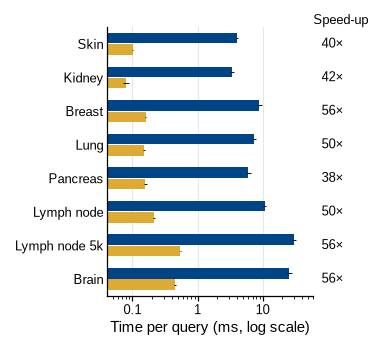

In [2]:
TIME_HANDLES = [Patch(color=NAIVE, label="Spindle-naive"), Patch(color=SPINDLE, label="Spindle")]


def panel_a(fig):
    ax = ps.axes(fig, left=17.0, right=10.0, bottom=BOTTOM, top=TOP_IN)
    t = timing
    bh = 0.34
    for i, k in enumerate(KEYS):
        r = t.loc[k]
        for off, col, c in ((-bh / 2, "naive_partial_search_ms", NAIVE), (bh / 2, "spindle_partial_ms", SPINDLE)):
            ax.barh(i + off, r[col], height=bh * 0.92, color=c, lw=0, zorder=2)
            ax.errorbar(r[col], i + off, xerr=r[f"{col}_sd"], fmt="none", ecolor=ps.INK, elinewidth=0.5, zorder=3)
    ax.set_xscale("log")
    ps.plain_log(ax, "x", subs=(1.0,))
    ps.log_grid(ax, "x")
    ax.set_xlim(t.spindle_partial_ms.min() / 2, t.naive_partial_search_ms.max() * 2)
    rows_axis(ax, True)
    ax.set_xlabel("Time per query (ms, log scale)")
    tr = blended_transform_factory(ax.transAxes, ax.transData)
    for i, k in enumerate(KEYS):
        ax.text(1.04, i, f"{t.loc[k].speedup_spindle_partial:.0f}×", transform=tr, ha="left", va="center",
                fontsize=ps.TICK_PT, clip_on=False)
    ax.text(1.0, 1.0, "Speed-up", transform=ax.transAxes, ha="left", va="bottom", fontsize=ps.TICK_PT)


fig = ps.panel(W_A, H)
panel_a(fig)
ps.save_panel(fig, FIG, "A")

## B · RDE and NNR against |S|, side by side

figures/fig4_gene_set/panels/B.pdf/.png: 68 x 60 mm, 0.0 / 0.3 MB


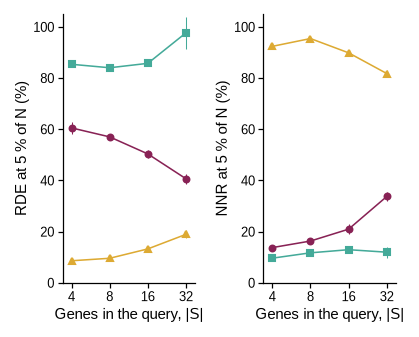

In [3]:
ACC_HANDLES = [Line2D([], [], marker=MARK[m], ms=2.8, color=COLOR[m], label=METHOD_LABEL[m])
               for m in ("spindle_partial", "padding", "imputation")]


def panel_b(fig):
    W, _ = ps.size_mm(fig)
    t = nx_size[nx_size["size"] > 0]
    w = W / 2
    for j, (col, ylabel) in enumerate((("NX5", "RDE at 5 % of N (%)"), ("overlap5", "NNR at 5 % of N (%)"))):
        ax = ps.axes(fig, left=j * w + 10.0, right=W - (j + 1) * w + 1.5, bottom=BOTTOM, top=TOP_IN)
        for m in ("padding", "imputation", "spindle_partial"):
            s = t[t.method == m].sort_values("size")
            ax.errorbar(s["size"], 100 * s[col], yerr=100 * s[f"{col}_sd"], fmt=f"-{MARK[m]}", ms=2.8,
                        color=COLOR[m], elinewidth=0.5, zorder=3 if m == "spindle_partial" else 2)
        ax.set_xscale("log", base=2)
        ax.set_xticks([4, 8, 16, 32], ["4", "8", "16", "32"])
        ax.minorticks_off()
        ax.set_xlim(3.4, 38)
        ax.set_ylim(0, 105)
        ax.set_xlabel("Genes in the query, |S|")
        ax.set_ylabel(ylabel)


fig = ps.panel(W_B, H)
panel_b(fig)
ps.save_panel(fig, FIG, "B")

## C · the typical breast query, with the budget

breast typical gene-set query: N = 1840, returned 309, budget c = 92, d_c = 0.298
figures/fig4_gene_set/panels/C.pdf/.png: 50 x 60 mm, 0.0 / 0.2 MB


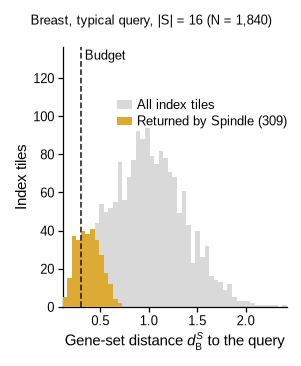

In [4]:
def panel_c(fig):
    d, found = band["d"], band["found"]
    c = rt.c5(len(d))
    budget = np.sort(d)[c - 1]
    print(f"breast typical gene-set query: N = {len(d)}, returned {len(found)}, budget c = {c}, d_c = {budget:.3f}")
    ax = ps.axes(fig, left=10.0, right=2.0, bottom=BOTTOM, top=TOP_IN + 1.5)
    bins = np.linspace(d.min(), np.quantile(d, 0.995), 50)
    n_all, _, _ = ax.hist(d, bins=bins, color=ps.LIGHT, lw=0, zorder=2, label="All index tiles")
    ax.hist(d[found], bins=bins, color=SPINDLE, lw=0, zorder=3, label=f"Returned by Spindle ({len(found)})")
    ax.axvline(budget, ls="--", lw=0.75, color=ps.INK, zorder=4)
    ax.set_ylim(0, 1.45 * n_all.max())
    ax.text(budget, 0.99, " Budget", transform=ax.get_xaxis_transform(), ha="left", va="top", fontsize=ps.TICK_PT)
    ax.legend(loc="upper right", bbox_to_anchor=(1.0, 0.8))
    ax.set_xlabel(r"Gene-set distance $d^{S}_{\mathcal{B}}$ to the query")
    ax.set_ylabel("Index tiles")
    ax.set_xlim(bins[0], bins[-1])
    _, h = ps.size_mm(fig)
    fig.text(0.5, 1 - 0.5 / h, f"Breast, typical query, |S| = 16 (N = {len(d):,})",
             ha="center", va="top", fontsize=ps.TICK_PT)


fig = ps.panel(W_C, H)
panel_c(fig)
ps.save_panel(fig, FIG, "C")

## Legends and full figure

figures/fig4_gene_set/panels/legend_A.pdf/.png: 62 x 11 mm, 0.0 / 0.0 MB
figures/fig4_gene_set/panels/legend_B.pdf/.png: 68 x 11 mm, 0.0 / 0.0 MB
breast typical gene-set query: N = 1840, returned 309, budget c = 92, d_c = 0.298
figures/fig4_gene_set/fig4_gene_set.pdf/.png: 180 x 71 mm, 0.0 / 0.8 MB


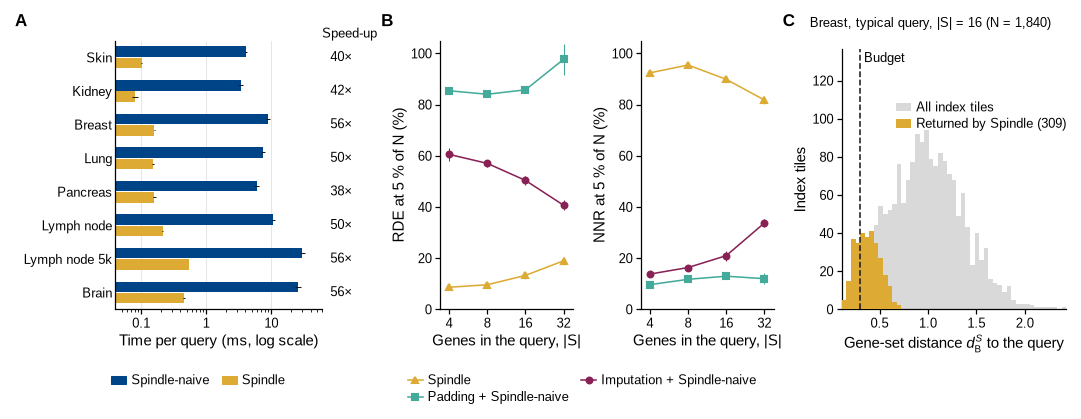

<Figure size 366.142x64.9606 with 0 Axes>

<Figure size 401.575x64.9606 with 0 Axes>

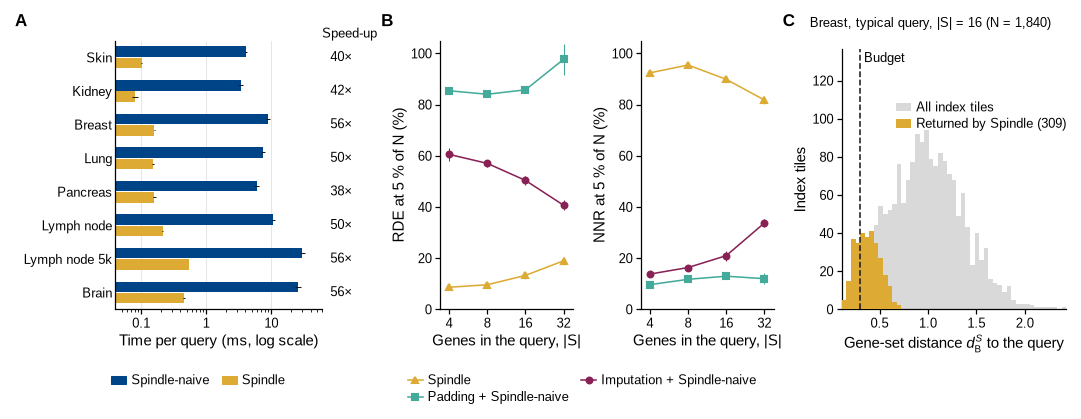

In [5]:
fig = ps.panel(W_A, LEG_H); legend(fig, TIME_HANDLES, 2); ps.save_panel(fig, FIG, "legend_A")
fig = ps.panel(W_B, LEG_H); legend(fig, ACC_HANDLES, 3); ps.save_panel(fig, FIG, "legend_B")

page = ps.page(180, H + LEG_H)
panel_a(ps.place(page, "A", 0, 0, W_A, H))
panel_b(ps.place(page, "B", W_A, 0, W_B, H))
panel_c(ps.place(page, "C", W_A + W_B, 0, W_C, H))
legend(ps.place(page, None, 0, H + 1.0, W_A, LEG_H - 1.0), TIME_HANDLES, 2)
legend(ps.place(page, None, W_A, H + 1.0, W_B, LEG_H - 1.0), ACC_HANDLES, 2)
ps.save_figure(page, FIG)
page